# Boston HMDA

The **Home Mortgage Disclosure Act (HMDA)** was passed by Congress in 1975 and requires lenders
to report information about the mortgages they make. A 1989 amendment expanded it to cover
applicants as well, to help identify possible discrimination in lending.

This dataset covers **mortgage applications made in 1990 in the greater Boston area**. The
Federal Reserve Bank of Boston combined the HMDA reports with a follow-up survey of lenders,
adding details such as credit history, debt ratios and wealth. This subset has 2,380
applications from Black and White applicants for single-family homes and condos.

**Target — `denied`:** 1 = denied, 0 = approved (originated, or approved but not accepted).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))


import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src.hmda.config import Cfg
from src.hmda.data_ingestion import clean, load_data

sns.set_theme(style="whitegrid")

df = clean(load_data(Cfg.data_path))
display(df.head())

,loan_amount,appraised_value,property_type,county,sex,applicant_income,expense_to_income,debt_to_income,fixed_rate,net_worth,...,pmi_sought,credit_meets_policy,unverifiable_information,marital_status,dependents,years_employed,years_on_job,housing_expense,education,denied
1,118,128.0,2,0,1.0,51.0,26.5,26.5,1.0,3.0,...,1,1.0,0,1.0,0,3.0,1.0,1161.0,18.0,0
2,185,201.0,2,0,1.0,99.0,24.8,37.2,1.0,22.0,...,0,1.0,0,0.0,0,13.0,14.0,2011.0,12.0,0
3,185,215.0,2,0,1.0,110.0,25.0,32.0,1.0,241.0,...,1,1.0,0,0.0,2,3.0,3.0,1937.0,12.0,0
4,330,550.0,2,0,1.0,129.0,35.0,36.0,1.0,365.0,...,0,1.0,0,0.0,1,17.0,11.0,3608.0,20.0,0
5,97,190.0,2,0,1.0,65.0,17.0,24.0,1.0,201.0,...,0,1.0,0,0.0,0,10.0,2.0,940.0,16.0,0


The table above is the **cleaned** data. Of the 62 columns in the original file, 32 were kept as features. Columns that never changed, were mostly missing, repeated another column, or were only recorded after the lending decision were left out.

Coded values were turned into numbers (for example, race: 1 = Black, 0 = White), and rows with missing values (`NA`, or the dataset's `999999.4` code) were dropped, leaving 2,226 of the 2,380 applications.

Source: Munnell, Tootell, Browne & McEneaney (1996), [*Mortgage Lending in Boston: Interpreting HMDA Data*](https://www.jstor.org/stable/2118254), *American Economic Review* 86(1), 25–53.

## Summary statistics

Count, mean, spread and range for every column in the cleaned data.

In [2]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
loan_amount,2226.0,139.88,83.29,2.00,95.00,123.00,158.00,980.00
appraised_value,2226.0,198.88,154.62,42.00,128.00,160.00,224.75,4316.00
property_type,2226.0,1.72,0.45,1.00,1.00,2.00,2.00,2.00
county,2226.0,0.17,0.38,0.00,0.00,0.00,0.00,1.00
sex,2226.0,0.79,0.40,0.00,1.00,1.00,1.00,1.00
applicant_income,2226.0,76.15,66.39,0.00,45.00,60.00,85.00,972.00
expense_to_income,2226.0,25.61,9.62,0.00,22.00,26.00,29.89,300.00
debt_to_income,2226.0,33.12,10.52,0.00,28.46,33.10,37.00,300.00
fixed_rate,2226.0,0.67,0.47,0.00,0.00,1.00,1.00,1.00
net_worth,2226.0,240.24,1035.97,-7919.00,38.00,83.00,210.75,28023.00


## Denied vs. approved

About 12% of applications were denied, so the classes are imbalanced: a model that always predicts "approved" would already be about 88% accurate.

/tmp/ipykernel_23470/3694350800.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(title="Applications by outcome", xticklabels=["Approved", "Denied"], xlabel="")


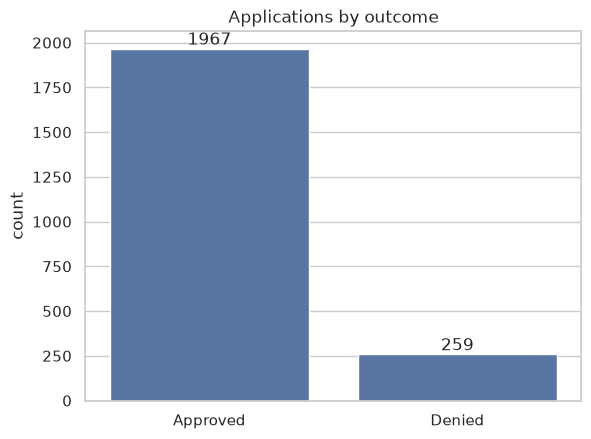

In [3]:
ax = sns.countplot(data=df, x="denied")
ax.bar_label(ax.containers[0])
ax.set(title="Applications by outcome", xticklabels=["Approved", "Denied"], xlabel="")
plt.show()

## Denial rate by consumer credit history

`chcp` grades the applicant's history on consumer debts such as credit cards and car loans:

1 = no late payments · 2 = one or two slow-pay accounts · 3 = more than two slow-pay accounts · 4 = not enough credit history · 5 = payments 60 days late · 6 = payments 90 days late

Each bar is the share of applicants with that grade who were denied.

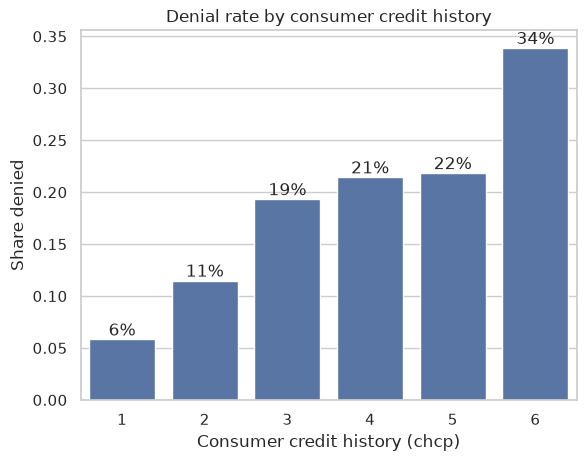

In [4]:
ax = sns.barplot(data=df, x="chcp", y="denied", errorbar=None)
ax.bar_label(ax.containers[0], fmt="{:.0%}")
ax.set(title="Denial rate by consumer credit history", xlabel="Consumer credit history (chcp)", ylabel="Share denied")
plt.show()

## Denial rate by mortgage credit history

`chmp` grades the applicant's history on past mortgage payments:

1 = no late mortgage payments · 2 = no mortgage payment history · 3 = one or two late mortgage payments · 4 = more than two late mortgage payments

Each bar is the share of applicants with that grade who were denied.

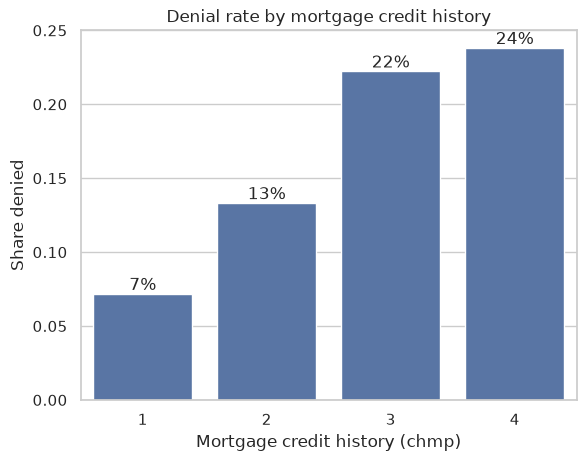

In [5]:
ax = sns.barplot(data=df, x="chmp", y="denied", errorbar=None)
ax.bar_label(ax.containers[0], fmt="{:.0%}")
ax.set(title="Denial rate by mortgage credit history", xlabel="Mortgage credit history (chmp)", ylabel="Share denied")
plt.show()

## Denial rate by public record

`public_record_history` shows whether the applicant has a bad public credit record:

0 = none · 1 = bankruptcy, charge-offs or collection actions

Each bar is the share of applicants in that group who were denied.

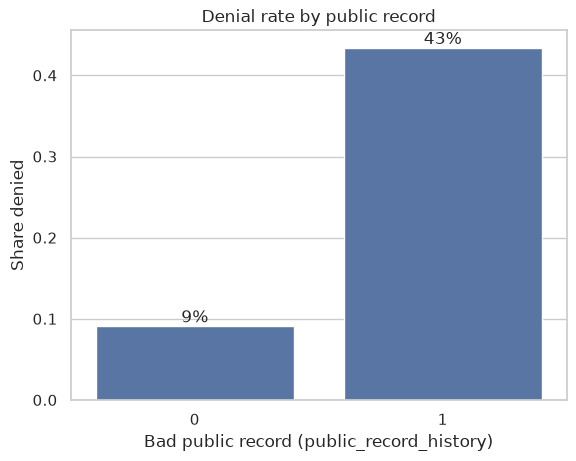

In [6]:
ax = sns.barplot(data=df, x="public_record_history", y="denied", errorbar=None)
ax.bar_label(ax.containers[0], fmt="{:.0%}")
ax.set(title="Denial rate by public record", xlabel="Bad public record (public_record_history)", ylabel="Share denied")
plt.show()

## Liquid assets

`liquid_assets` is the applicant's cash and easy-to-sell savings, in thousands of dollars. Each box covers the middle half of applicants, and the line inside is the median. Extreme values are hidden so the boxes are readable.

/tmp/ipykernel_23470/2306319489.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(title="Liquid assets", xticklabels=["Approved", "Denied"], xlabel="", ylabel="Liquid assets ($ thousands)")


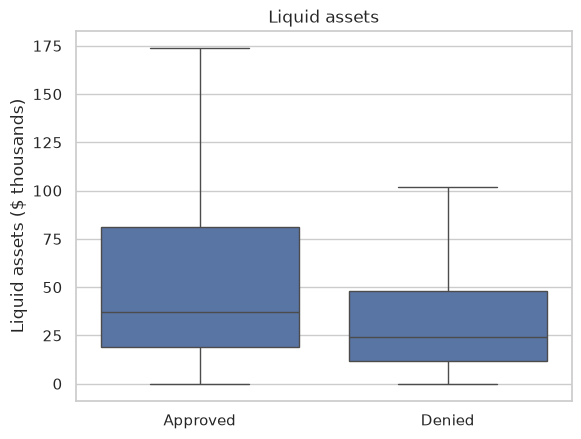

In [7]:
ax = sns.boxplot(data=df, x="denied", y="liquid_assets", showfliers=False)
ax.set(title="Liquid assets", xticklabels=["Approved", "Denied"], xlabel="", ylabel="Liquid assets ($ thousands)")
plt.show()

## Applicant income

Yearly income of the applicant, in thousands of dollars. Most incomes are bunched together, with a long tail of high earners. The dashed line marks the median. The plot shows incomes up to $300k.

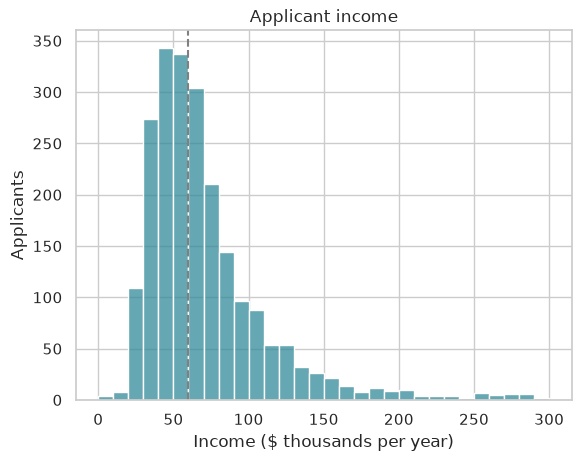

In [8]:
ax = sns.histplot(data=df, x="applicant_income", binwidth=10, binrange=(0, 300), color="#318A9A")
ax.axvline(df["applicant_income"].median(), linestyle="--", color="gray")
ax.set(title="Applicant income", xlabel="Income ($ thousands per year)", ylabel="Applicants")
plt.show()

## Denial rate by private mortgage insurance (PMI) outcome

Buyers with a small down payment usually need private mortgage insurance. `pmi_denied` shows whether the insurer turned them down:

0 = PMI approved, not needed, or not recorded · 1 = PMI sought and denied

Each bar is the share of applicants in that group who were denied the mortgage.

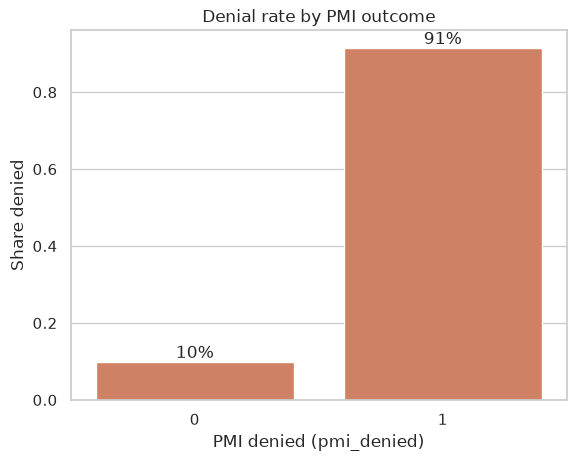

In [9]:
ax = sns.barplot(data=df, x="pmi_denied", y="denied", errorbar=None, color="#DF7953")
ax.bar_label(ax.containers[0], fmt="{:.0%}")
ax.set(title="Denial rate by PMI outcome", xlabel="PMI denied (pmi_denied)", ylabel="Share denied")
plt.show()

## Dependents by marital status

How many dependents applicants claimed, split by marital status (`marital_status`: Married, Unmarried, Separated).

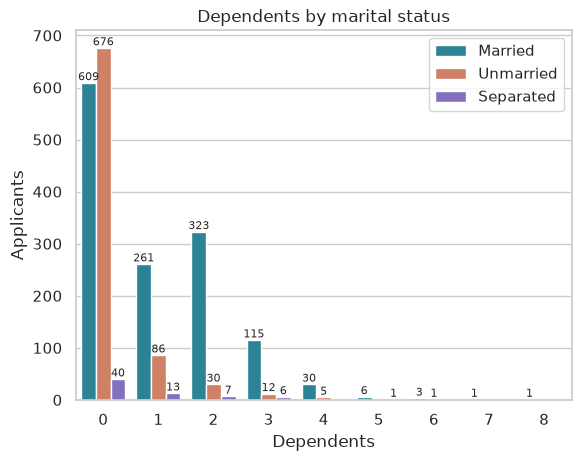

In [10]:
ax = sns.countplot(data=df, x="dependents", hue="marital_status", palette=["#1A8FA6", "#DF7953", "#7E62CC"])
for bars in ax.containers:
    ax.bar_label(bars, fontsize=8)
ax.legend(ax.get_legend().legend_handles, ["Married", "Unmarried", "Separated"], title="")
ax.set(title="Dependents by marital status", xlabel="Dependents", ylabel="Applicants")
plt.show()